# 01 - Baselines for 1D magnetic diffusion

Milestone M1 of `SPEC.md`. This notebook builds the reference solutions the PINN will be judged against:

1. Analytic solutions (series and method-of-images forms).
2. A finite-difference (FD) solver with Crank-Nicolson time stepping and an optional backward-Euler start-up, whose usefulness we test rather than assume.
3. Verification: analytic forms agree with each other, FD converges at second order on the smooth problem, and FD error on the step problem is measured.

Nondimensional PDE: $\partial_\tau b = \partial_\xi^2 b$ on $0<\xi<1$, with $b=B/B_0$, $\xi=x/L$, $\tau=\eta t/L^2$ and $\eta = 1/(\mu_0\sigma)$.

| Variant | $b(\xi,0)$ | $b(0,\tau)$ | $b(1,\tau)$ |
|---|---|---|---|
| S (smooth) | $\sin\pi\xi$ | 0 | 0 |
| A (step) | 0 | 1 | 0 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.special import erfc

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Analytic solutions

**Variant S:** $b = \sin(\pi\xi)\,e^{-\pi^2\tau}$.

**Variant A, series form:** $b = 1-\xi-\sum_{n\ge1}\frac{2}{n\pi}\sin(n\pi\xi)\,e^{-n^2\pi^2\tau}$. It converges quickly for moderate $\tau$ but needs many terms (and shows Gibbs ringing) at small $\tau$.

**Variant A, images form:** $b=\sum_{k\ge0}\left[\operatorname{erfc}\frac{2k+\xi}{2\sqrt\tau}-\operatorname{erfc}\frac{2k+2-\xi}{2\sqrt\tau}\right]$. It converges quickly at small $\tau$. Using both forms gives an independent cross-check.

In [2]:
def exact_S(xi, tau):
    xi = np.asarray(xi, dtype=float)
    tau = np.asarray(tau, dtype=float)
    return np.sin(np.pi * xi) * np.exp(-np.pi**2 * tau)


def exact_A_series(xi, tau, nmax=4000):
    xi = np.asarray(xi, dtype=float)
    tau = np.asarray(tau, dtype=float)
    n = np.arange(1, nmax + 1)
    xi_b, tau_b = np.broadcast_arrays(xi, tau)
    flat_xi, flat_tau = xi_b.ravel(), tau_b.ravel()
    out = np.empty_like(flat_xi)
    for start in range(0, flat_xi.size, 2000):  # chunk to bound memory
        sl = slice(start, start + 2000)
        terms = (2.0 / (n * np.pi)) * np.sin(np.outer(flat_xi[sl], n) * np.pi) \
            * np.exp(-np.outer(flat_tau[sl], n**2) * np.pi**2)
        out[sl] = 1.0 - flat_xi[sl] - terms.sum(axis=1)
    return out.reshape(xi_b.shape)


def exact_A_images(xi, tau, kmax=60):
    xi = np.asarray(xi, dtype=float)
    tau = np.asarray(tau, dtype=float)
    s = 2.0 * np.sqrt(tau)
    k = np.arange(0, kmax + 1)
    xi_b, s_b = np.broadcast_arrays(xi, s)
    total = np.zeros_like(xi_b, dtype=float)
    for kk in k:
        total += erfc((2 * kk + xi_b) / s_b) - erfc((2 * kk + 2 - xi_b) / s_b)
    return total

### Verification of the analytic solutions

In [3]:
xi = np.linspace(0.0, 1.0, 401)

# 1) The two forms of A agree where both are accurate.
for tau in [0.002, 0.01, 0.05, 0.2]:
    d = np.max(np.abs(exact_A_series(xi, tau) - exact_A_images(xi, tau)))
    print(f"tau={tau:<6} max |series - images| = {d:.2e}")

# 2) Boundary conditions (tau > 0).
tau = 0.05
print("\nBC check at tau=0.05:",
      f"b(0)={exact_A_images(0.0, tau):.12f}, b(1)={exact_A_images(1.0, tau):.3e}")

# 3) PDE residual by central differences (smooth interior, moderate tau).
def pde_residual(f, xi0, tau0, h=1e-3, dt=1e-5):
    dbdt = (f(xi0, tau0 + dt) - f(xi0, tau0 - dt)) / (2 * dt)
    d2b = (f(xi0 + h, tau0) - 2 * f(xi0, tau0) + f(xi0 - h, tau0)) / h**2
    return dbdt - d2b

x0 = np.linspace(0.1, 0.9, 9)
for name, f in [("S", exact_S), ("A (images)", exact_A_images)]:
    r = pde_residual(f, x0, 0.05)
    print(f"{name:<11} max |db/dtau - d2b/dxi2| = {np.max(np.abs(r)):.2e}")

tau=0.002  max |series - images| = 5.00e-16
tau=0.01   max |series - images| = 2.56e-16
tau=0.05   max |series - images| = 2.78e-16
tau=0.2    max |series - images| = 2.22e-16

BC check at tau=0.05: b(0)=1.000000000000, b(1)=0.000e+00
S           max |db/dtau - d2b/dxi2| = 4.97e-06
A (images)  max |db/dtau - d2b/dxi2| = 9.03e-06


The series form is used for $\tau \gtrsim 0.01$ and the images form for smaller $\tau$. The image form is also fine at larger $\tau$, so the default reference below is the images form with the series as the check.

## 2. Finite-difference solver

Second-order central differences in $\xi$ on $N$ intervals ($h=1/N$) and a $\theta$-scheme in time. Crank-Nicolson ($\theta=1/2$) is second-order accurate but does not damp high-frequency content, so for some discontinuous data it can ring. The standard remedy (Rannacher start-up) is to take the first few steps with backward Euler ($\theta=1$) at half the step size, then switch to CN. The option is included as `rannacher=True`; section 3 checks whether problem A actually needs it.

In [4]:
def fd_solve(N, nsteps, tau_end, variant="S", rannacher=False, return_history=False):
    '''Solve db/dtau = d2b/dxi2 on [0,1] with N intervals and nsteps time steps up to tau_end.

    Returns xi (N+1,) and b at tau_end (N+1,). If return_history, also returns
    the times and the full (nsteps_total+1, N+1) array.
    '''
    h = 1.0 / N
    xi = np.linspace(0.0, 1.0, N + 1)
    left = 1.0 if variant == "A" else 0.0   # Dirichlet value at xi=0 for tau>0
    right = 0.0
    u = np.sin(np.pi * xi) if variant == "S" else np.zeros_like(xi)
    u[0], u[-1] = left, right
    # At tau=0 the data in A are discontinuous at the corner; the interior starts at 0.

    m = N - 1  # interior unknowns

    def step(u, dt, theta):
        r = dt / h**2
        # LHS: (I - theta*r*L) u^{n+1};  RHS: (I + (1-theta)*r*L) u^n + boundary terms
        ab = np.zeros((3, m))
        ab[0, 1:] = -theta * r
        ab[1, :] = 1 + 2 * theta * r
        ab[2, :-1] = -theta * r
        ui = u[1:-1]
        rhs = ui + (1 - theta) * r * (u[:-2] - 2 * ui + u[2:])
        rhs[0] += theta * r * left
        rhs[-1] += theta * r * right
        new = u.copy()
        new[1:-1] = solve_banded((1, 1), ab, rhs)
        new[0], new[-1] = left, right
        return new

    dt = tau_end / nsteps
    times = [0.0]
    hist = [u.copy()]
    t = 0.0
    n_start = 2 if (rannacher and nsteps >= 4) else 0
    for _ in range(n_start):          # each CN step replaced by two BE half-steps
        for _ in range(2):
            u = step(u, dt / 2, 1.0)
            t += dt / 2
            times.append(t); hist.append(u.copy())
    for _ in range(nsteps - n_start):
        u = step(u, dt, 0.5)
        t += dt
        times.append(t); hist.append(u.copy())
    if return_history:
        return xi, np.array(times), np.array(hist)
    return xi, u

### Profiles for the two variants

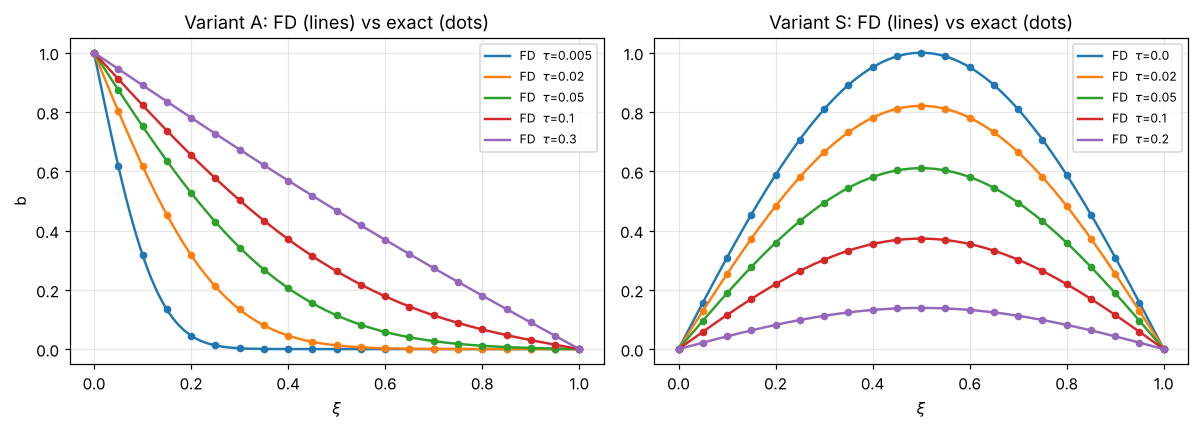

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)

taus = [0.005, 0.02, 0.05, 0.1, 0.3]
for tau in taus:
    xi_fd, u = fd_solve(400, 400, tau, "A")
    p, = axes[0].plot(xi_fd, u, lw=1.6, label=fr"FD  $\tau$={tau}")
    axes[0].plot(xi_fd[::20], exact_A_images(xi_fd[::20], tau), "o", ms=4, color=p.get_color())
axes[0].set(title="Variant A: FD (lines) vs exact (dots)", xlabel=r"$\xi$", ylabel="b")
axes[0].legend(fontsize=8)

for tau in [0.0, 0.02, 0.05, 0.1, 0.2]:
    xi_fd, u = fd_solve(400, 400, tau if tau > 0 else 1e-9, "S")
    p, = axes[1].plot(xi_fd, u, lw=1.6, label=fr"FD  $\tau$={tau}")
    axes[1].plot(xi_fd[::20], exact_S(xi_fd[::20], tau), "o", ms=4, color=p.get_color())
axes[1].set(title="Variant S: FD (lines) vs exact (dots)", xlabel=r"$\xi$")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Convergence studies

**Variant S** (smooth): refine space and time together ($\Delta\tau \propto h$ is enough for CN, since both errors are second order in their step). Expected slope: 2 on a log-log plot.

**Variant A** (step): the jump between the initial data and the boundary value could limit accuracy or cause ringing. We measure CN with and without the start-up at a fixed $\tau$, and separately check early times for oscillations (negative values), to see what accuracy the reference actually has.

In [6]:
def rel_l2(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

tau_S = 0.1
Ns = np.array([10, 20, 40, 80, 160, 320, 640])
errS = []
for N in Ns:
    xi_fd, u = fd_solve(N, N, tau_S, "S")
    errS.append(rel_l2(u, exact_S(xi_fd, tau_S)))
errS = np.array(errS)
slopeS = np.polyfit(np.log(1.0 / Ns), np.log(errS), 1)[0]

print(f"Variant S, tau={tau_S}")
print(f"{'N':>5} {'rel L2 error':>14} {'observed order':>16}")
for i, N in enumerate(Ns):
    order = "" if i == 0 else f"{np.log(errS[i-1]/errS[i])/np.log(2):.2f}"
    print(f"{N:>5} {errS[i]:>14.3e} {order:>16}")
print(f"least-squares slope: {slopeS:.2f}")

Variant S, tau=0.1
    N   rel L2 error   observed order
   10      7.335e-03                 
   20      1.830e-03             2.00
   40      4.573e-04             2.00
   80      1.143e-04             2.00
  160      2.858e-05             2.00
  320      7.145e-06             2.00
  640      1.786e-06             2.00
least-squares slope: 2.00


Variant A, tau=0.05
    N   with start-up     plain CN  order (plain)
   10       3.797e-03    3.252e-03               
   20       1.027e-03    8.739e-04           1.90
   40       2.673e-04    2.272e-04           1.94
   80       6.822e-05    5.796e-05           1.97
  160       1.723e-05    1.464e-05           1.99
  320       4.331e-06    3.679e-06           1.99
  640       1.086e-06    9.223e-07           2.00


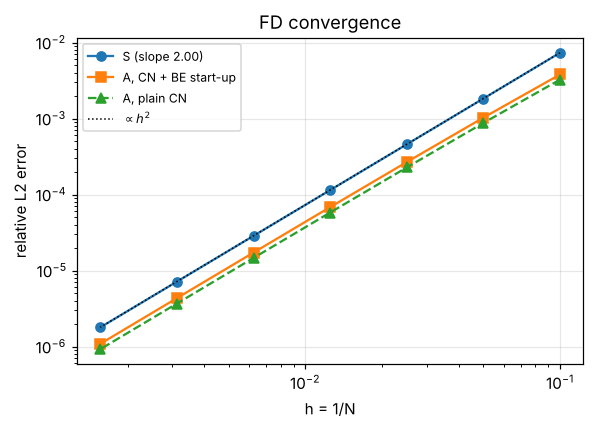

In [7]:
tau_A = 0.05
errA, errA_noR = [], []
for N in Ns:
    xi_fd, u = fd_solve(N, N, tau_A, "A", rannacher=True)
    errA.append(rel_l2(u, exact_A_images(xi_fd, tau_A)))
    xi_fd, u = fd_solve(N, N, tau_A, "A", rannacher=False)
    errA_noR.append(rel_l2(u, exact_A_images(xi_fd, tau_A)))
errA, errA_noR = np.array(errA), np.array(errA_noR)

print(f"Variant A, tau={tau_A}")
print(f"{'N':>5} {'with start-up':>15} {'plain CN':>12} {'order (plain)':>14}")
for i, N in enumerate(Ns):
    order = "" if i == 0 else f"{np.log(errA_noR[i-1]/errA_noR[i])/np.log(2):.2f}"
    print(f"{N:>5} {errA[i]:>15.3e} {errA_noR[i]:>12.3e} {order:>14}")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(1.0 / Ns, errS, "o-", label=f"S (slope {slopeS:.2f})")
ax.loglog(1.0 / Ns, errA, "s-", label="A, CN + BE start-up")
ax.loglog(1.0 / Ns, errA_noR, "^--", label="A, plain CN")
ax.loglog(1.0 / Ns, errS[0] * (Ns[0] / Ns)**2, "k:", lw=1, label=r"$\propto h^2$")
ax.set(xlabel="h = 1/N", ylabel="relative L2 error", title="FD convergence")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Does problem A ring?

If plain CN rang, the solution would dip below 0 or above 1 at early times. Check a range of early $\tau$ at a fine grid, with and without the start-up.

In [8]:
print(f"{'tau':>8} {'start-up':>9} {'min(b)':>11} {'max(b)':>9} {'max|err|':>10}")
for tau in [0.0002, 0.0005, 0.002, 0.01]:
    for ran in [False, True]:
        xi_fd, u = fd_solve(320, 320, tau, "A", rannacher=ran)
        err = np.max(np.abs(u - exact_A_images(xi_fd, tau)))
        print(f"{tau:>8} {str(ran):>9} {u.min():>11.2e} {u.max():>9.4f} {err:>10.2e}")

     tau  start-up      min(b)    max(b)   max|err|
  0.0002     False    0.00e+00    1.0000   6.60e-04
  0.0002      True    0.00e+00    1.0000   6.60e-04
  0.0005     False    0.00e+00    1.0000   2.64e-04
  0.0005      True    0.00e+00    1.0000   2.64e-04
   0.002     False    0.00e+00    1.0000   6.61e-05
   0.002      True    0.00e+00    1.0000   6.63e-05
    0.01     False    0.00e+00    1.0000   1.31e-05
    0.01      True    0.00e+00    1.0000   1.33e-05


Neither variant produces values outside $[0,1]$, and the errors agree to within a few percent. For this boundary-driven step, plain CN is adequate, so the reference solver uses it by default (`rannacher=False`). The start-up stays available for harder data later (for example a discontinuous interior initial condition).

## 4. Reference fields for later notebooks

A fixed evaluation grid in $(\xi,\tau)$ keeps all later comparisons on equal terms. We store the exact fields (images form for A) on a $201\times201$ grid with $\tau\in(0,0.5]$ so every PINN notebook loads the same targets.

max |ref_A(tau=0.5) - FD| : 0.0012264324213079325


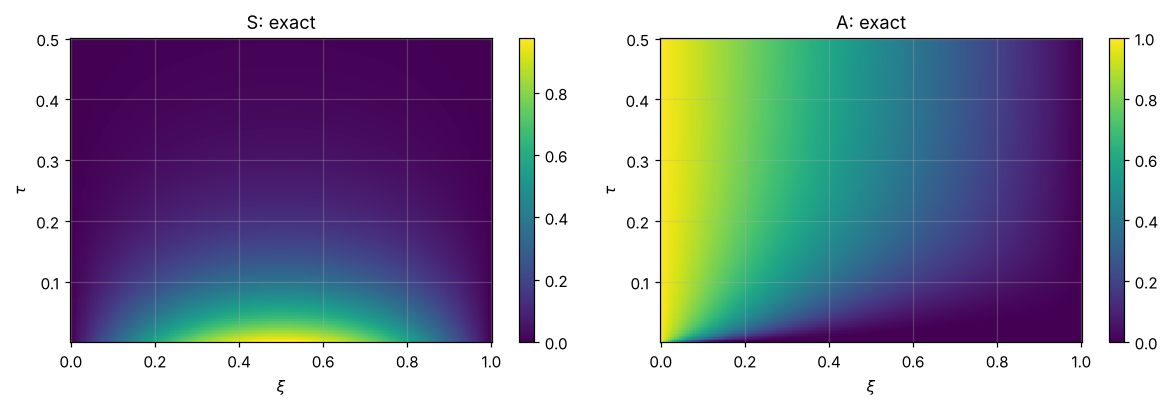

saved ../data/reference_fields.npz


In [9]:
xi_eval = np.linspace(0.0, 1.0, 201)
tau_eval = np.linspace(0.0, 0.5, 201)[1:]      # exclude tau=0 (discontinuous data in A)
XI, TAU = np.meshgrid(xi_eval, tau_eval)       # shape (200, 201)

ref_S = exact_S(XI, TAU)
ref_A = exact_A_images(XI, TAU)

# Check the stored reference for A against the FD solution at the final time.
xi_fd, u_end = fd_solve(800, 800, 0.5, "A")
print("max |ref_A(tau=0.5) - FD| :", np.max(np.abs(np.interp(xi_eval, xi_fd, u_end) - ref_A[-1])))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, ref, title in zip(axes, [ref_S, ref_A], ["S: exact", "A: exact"]):
    im = ax.pcolormesh(xi_eval, tau_eval, ref, shading="auto", cmap="viridis")
    ax.set(xlabel=r"$\xi$", ylabel=r"$\tau$", title=title)
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

import os
os.makedirs("../data", exist_ok=True)
np.savez("../data/reference_fields.npz", xi=xi_eval, tau=tau_eval, ref_S=ref_S, ref_A=ref_A)
print("saved ../data/reference_fields.npz")

## 5. Physical units (for reporting)

With $\eta = 1/(\mu_0\sigma)$, a nondimensional time $\tau$ corresponds to $t=\tau L^2/\eta$. For orientation, aluminum ($\sigma\approx3.5\times10^7$ S/m) and a 5 mm thick wall:

In [10]:
mu0 = 4e-7 * np.pi
sigma_al = 3.5e7          # S/m, approximate
L = 5e-3                  # m
eta = 1.0 / (mu0 * sigma_al)
t_diff = L**2 / eta
print(f"eta = {eta:.4f} m^2/s")
print(f"diffusion time L^2/eta = {t_diff*1e3:.3f} ms  (tau = 1)")
print(f"tau = 0.5 corresponds to t = {0.5*t_diff*1e3:.3f} ms")

eta = 0.0227 m^2/s
diffusion time L^2/eta = 1.100 ms  (tau = 1)
tau = 0.5 corresponds to t = 0.550 ms


## Summary

- Both analytic forms of A agree; S and A satisfy the PDE and boundary conditions (checks above).
- FD with CN converges at second order on S. On A it also converges at second order in relative L2 error, shows no oscillations, and gets no benefit from the backward-Euler start-up; the error tables above are the accuracy of the reference a PINN is compared with.
- Reference fields are stored in `data/reference_fields.npz` for use by the PINN notebooks.

Next: `02_plain_pinn.ipynb` (M2).